<a href="https://colab.research.google.com/github/jawahirkhaleel/-jawahirkhaleel-/blob/main/La_Cumbre_Volcano_Eruption_2020.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## La Cumbre Volcano Eruption, Galápagos, Ecuador (2020)

Part of the [InSAR.dev](https://insar.dev) Python ecosystem for SAR and InSAR processing. Free for personal and educational purposes; professional/funded use requires an active [license](https://pechnikov.dev).

### Resources
- Documentation and examples on [Patreon](https://www.patreon.com/pechnikov)
- Source code on [GitHub](https://github.com/InSARdev)
- Docker images on [DockerHub](https://hub.docker.com/r/insardev/)
- Updates on [LinkedIn](https://www.linkedin.com/in/alexey-pechnikov/)
- Tutorials on [YouTube](https://www.youtube.com/@alexeypechnikov)

© InSAR.dev, 2026

$\large\color{blue}{\text{Hint: Use menu Cell} \to \text{Run All or Runtime} \to \text{Complete All or Runtime} \to \text{Run All}}$
$\large\color{blue}{\text{(depending of your localization settings) to execute the entire notebook}}$

La Cumbre is the shield volcano that forms Fernandina Island, the most active volcano of the
Galápagos archipelago, Ecuador. A short eruption on 12–13 January 2020 opened a fissure on the
upper flank near the summit caldera, and the magma intrusion that fed it deformed the volcano by
tens of centimetres.

A single Sentinel-1 interferogram spanning the eruption — 2020-01-10 (Sentinel-1B) and
2020-01-16 (Sentinel-1A), descending orbit — maps that deformation. The notebook builds it from
eight bursts, unwraps it, converts it to line-of-sight (LOS) displacement and compares the result
to the map published by the Instituto Geofísico, Escuela Politécnica Nacional (IG-EPN).

# Stage 1 — Pre-processing: Sentinel-1 SLC to a geocoded Zarr stack

`insardev_pygmtsar` downloads the bursts and their orbits, coregisters them against a reference
date and writes a geocoded, chunked Zarr stack that can be hosted anywhere — locally, on GitHub,
or as a single ZIP archive.

## Google Colab installation

In [ ]:
import sys, os
if 'google.colab' in sys.modules:
  #!{sys.executable} -m pip install -qq --progress-bar off insardev-toolkit insardev-pygmtsar
  !{sys.executable} -m pip install -qq --progress-bar off \
    "insardev_toolkit  @ git+https://github.com/InSARdev/core@main#subdirectory=insardev_toolkit" \
    "insardev_pygmtsar @ git+https://github.com/InSARdev/core@main#subdirectory=insardev_pygmtsar"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Import Python modules

In [ ]:
import numpy as np
import geopandas as gpd
import shapely
import json
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
# import modules to be used in the notebook
from insardev_pygmtsar import S1
from insardev_toolkit import UI, EOF, ASF, Tiles, XYZTiles
UI('dark')

## Area and bursts

The area of interest (AOI) outlines Fernandina Island. `ASF.search()` finds every Sentinel-1
burst that covers it on the two descending passes around the eruption.

In [ ]:
# Fernandina Island outline
geojson = '''
{
  "type": "Feature",
  "geometry": {
    "type": "Polygon",
    "coordinates": [[
      [-91.43, -0.5],
      [-91.38, -0.36],
      [-91.46, -0.26],
      [-91.66, -0.3],
      [-91.65, -0.4],
      [-91.43, -0.5]
    ]]
  },
  "properties": {}
}
'''
AOI = gpd.GeoDataFrame.from_features([json.loads(geojson)])

In [ ]:
# find bursts on the descending passes before and after the eruption;
# the AOI shrunk by 0.02° skips the bursts that only touch the coast
bursts = ASF.search(AOI.buffer(-0.02), startTime='2020-01-10', stopTime='2020-01-16', flightDirection='D', polarization='VV')
bursts

,geometry,centerLat,centerLon,stopTime,fileID,flightDirection,pathNumber,processingLevel,url,startTime,...,processingDate,sensor,groupID,pgeVersion,fileName,beamModeType,s3Urls,burst,additionalUrls,fullBurstID
0,"POLYGON ((-91.50864 -0.4262, -91.91772 -0.3358...",-0.431774,-91.928831,2020-01-16T11:50:32Z,S1_273867_IW2_20200116T115028_VV_D200-BURST,DESCENDING,128,BURST,https://sentinel1-burst.asf.alaska.edu/S1A_IW_...,2020-01-16T11:50:29Z,...,None,C-SAR,S1A_IWDV_0592_0599_030825_128,003.10,S1_273867_IW2_20200116T115028_VV_D200-BURST.tiff,IW,[],"{'absoluteBurstID': 66208809, 'relativeBurstID...",[https://sentinel1-burst.asf.alaska.edu/S1A_IW...,128_273867_IW2
1,"POLYGON ((-90.75906 -0.52181, -91.15246 -0.434...",-0.536820,-91.161835,2020-01-16T11:50:31Z,S1_273867_IW1_20200116T115027_VV_D200-BURST,DESCENDING,128,BURST,https://sentinel1-burst.asf.alaska.edu/S1A_IW_...,2020-01-16T11:50:28Z,...,None,C-SAR,S1A_IWDV_0592_0599_030825_128,003.10,S1_273867_IW1_20200116T115027_VV_D200-BURST.tiff,IW,[],"{'absoluteBurstID': 66208809, 'relativeBurstID...",[https://sentinel1-burst.asf.alaska.edu/S1A_IW...,128_273867_IW1
2,"POLYGON ((-91.47352 -0.25953, -91.88258 -0.169...",-0.265201,-91.893677,2020-01-16T11:50:29Z,S1_273866_IW2_20200116T115025_VV_D200-BURST,DESCENDING,128,BURST,https://sentinel1-burst.asf.alaska.edu/S1A_IW_...,2020-01-16T11:50:26Z,...,None,C-SAR,S1A_IWDV_0592_0599_030825_128,003.10,S1_273866_IW2_20200116T115025_VV_D200-BURST.tiff,IW,[],"{'absoluteBurstID': 66208808, 'relativeBurstID...",[https://sentinel1-burst.asf.alaska.edu/S1A_IW...,128_273866_IW2
3,"POLYGON ((-90.72401 -0.35499, -91.11737 -0.268...",-0.370075,-91.126734,2020-01-16T11:50:28Z,S1_273866_IW1_20200116T115024_VV_D200-BURST,DESCENDING,128,BURST,https://sentinel1-burst.asf.alaska.edu/S1A_IW_...,2020-01-16T11:50:25Z,...,None,C-SAR,S1A_IWDV_0592_0599_030825_128,003.10,S1_273866_IW1_20200116T115024_VV_D200-BURST.tiff,IW,[],"{'absoluteBurstID': 66208808, 'relativeBurstID...",[https://sentinel1-burst.asf.alaska.edu/S1A_IW...,128_273866_IW1
4,"POLYGON ((-91.50864 -0.4262, -91.91772 -0.3358...",-0.431774,-91.928831,2020-01-10T11:49:50Z,S1_273867_IW2_20200110T114946_VV_5E5F-BURST,DESCENDING,128,BURST,https://sentinel1-burst.asf.alaska.edu/S1B_IW_...,2020-01-10T11:49:47Z,...,None,C-SAR,S1B_IWDV_0590_0597_019754_128,003.10,S1_273867_IW2_20200110T114946_VV_5E5F-BURST.tiff,IW,[],"{'absoluteBurstID': 42429099, 'relativeBurstID...",[https://sentinel1-burst.asf.alaska.edu/S1B_IW...,128_273867_IW2
5,"POLYGON ((-90.75906 -0.52181, -91.15246 -0.434...",-0.536820,-91.161835,2020-01-10T11:49:49Z,S1_273867_IW1_20200110T114945_VV_5E5F-BURST,DESCENDING,128,BURST,https://sentinel1-burst.asf.alaska.edu/S1B_IW_...,2020-01-10T11:49:46Z,...,None,C-SAR,S1B_IWDV_0590_0597_019754_128,003.10,S1_273867_IW1_20200110T114945_VV_5E5F-BURST.tiff,IW,[],"{'absoluteBurstID': 42429099, 'relativeBurstID...",[https://sentinel1-burst.asf.alaska.edu/S1B_IW...,128_273867_IW1
6,"POLYGON ((-91.47352 -0.25953, -91.88258 -0.169...",-0.265201,-91.893677,2020-01-10T11:49:47Z,S1_273866_IW2_20200110T114943_VV_5E5F-BURST,DESCENDING,128,BURST,https://sentinel1-burst.asf.alaska.edu/S1B_IW_...,2020-01-10T11:49:44Z,...,None,C-SAR,S1B_IWDV_0590_0597_019754_128,003.10,S1_273866_IW2_20200110T114943_VV_5E5F-BURST.tiff,IW,[],"{'absoluteBurstID': 42429098, 'relativeBurstID...",[https://sentinel1-burst.asf.alaska.edu/S1B_IW...,128_273866_IW2
7,"POLYGON ((-90.72401 -0.35499, -91.11737 -0.268...",-0.370075,-91.126734,2020-01-10T11:49:47Z,S1_273866_IW1_20200110T114942_VV_5E5F-BURST,DESCENDING,128,BURST,https://sentinel1-burst.asf.alaska.edu/S1B_IW_...,2020-01-10T11:49:44Z,...,None,C-SAR,S1B_IWDV_0590_0597_019754_128,003.10,S1_273866_IW1_20200110T114942_VV_5E5F-BURST.tiff,IW,[],"{'absoluteBurstID': 42429098, 'relativeBurstID...",[https://sentinel1-burst.asf.alaska.edu/S1B_IW...,128_273866_IW1


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


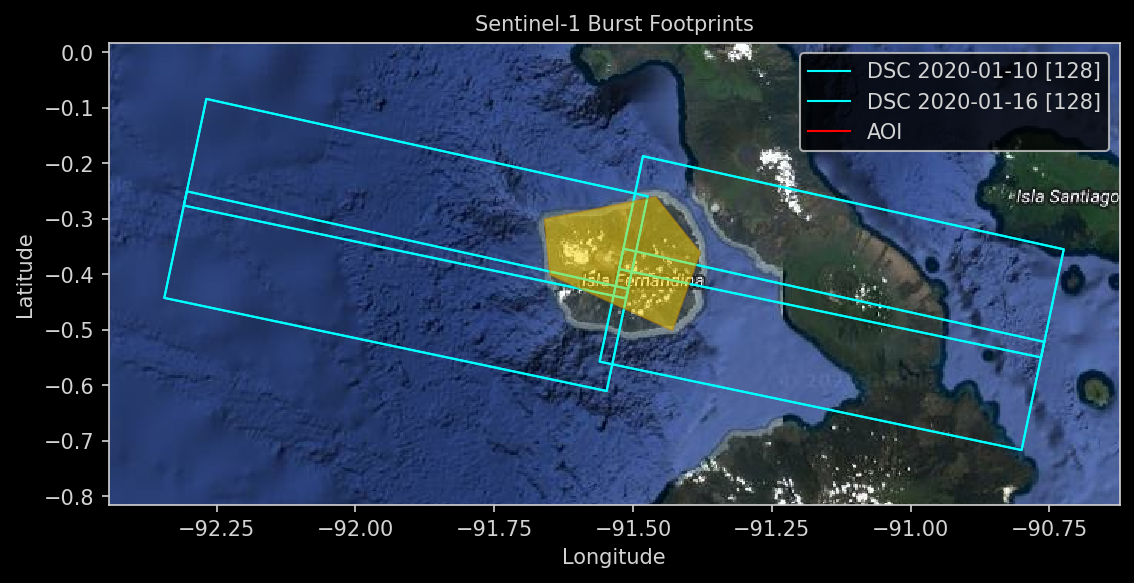

In [ ]:
plt.figure()
# plot basemap
XYZTiles().download_googlesatellitehybrid(bursts.union_all().buffer(0.1), zoom=9).plot.imshow(ax=plt.gca())
# plot bursts
ASF.plot(bursts, ax=plt.gca())
# plot AOI
AOI.plot(ax=plt.gca(), color='gold', edgecolor='darkgoldenrod', alpha=0.5, label='AOI')
plt.gca().set_aspect('equal')
plt.show()

In [ ]:
# print bursts
BURSTS = bursts.fileID.tolist()
print (f'Bursts defined: {len(BURSTS)}')

Bursts defined: 8


## Directories

In [ ]:
# directory where Sentinel-1 bursts and orbits will be downloaded
DATADIR = 'lacumbre_data'
# path to the downloaded DEM file
DEM = f'{DATADIR}/dem.vrt'
ZARRDIR = 'lacumbre_zarr'

## Download bursts, orbits and DEM

An empty `ASF()` pulls the bursts from the InSAR.dev cache; pass your Earthdata credentials as
`ASF(user, password)` to download from ASF directly. Precise orbits and a Copernicus GLO-30 DEM
follow — the DEM both geocodes the SLCs and supplies the topographic phase removed from the
interferogram.

In [ ]:
# leave empty to download bursts from InSAR.dev global cache (faster) or use your ASF username and password
asf = ASF()
asf.download(DATADIR, BURSTS, polarization='VV')

NOTE: Using insar.dev Cache API. Free for non-commercial use; license required for funded academic, institutional, or professional use.


,burst
0,S1_273867_IW2_20200116T115028_VV_D200-BURST
1,S1_273867_IW1_20200116T115027_VV_D200-BURST
2,S1_273866_IW2_20200116T115025_VV_D200-BURST
3,S1_273866_IW1_20200116T115024_VV_D200-BURST
4,S1_273867_IW2_20200110T114946_VV_5E5F-BURST
5,S1_273867_IW1_20200110T114945_VV_5E5F-BURST
6,S1_273866_IW2_20200110T114943_VV_5E5F-BURST
7,S1_273866_IW1_20200110T114942_VV_5E5F-BURST


In [ ]:
# read the notices printed below carefully
s1 = S1(DATADIR)
s1

NOTE: Loaded 8 bursts.
NOTE: Orbits are not downloaded, baselines are undefined. Download the orbits and scan the data directory again.


Object S1 8 items
                                                                                         startTime  \
fullBurstID    polarization burst                                                                    
128_273866_IW1 VV           S1_273866_IW1_20200110T114942_VV_5E5F-BURST 2020-01-10 11:49:42.916787   
                            S1_273866_IW1_20200116T115024_VV_D200-BURST 2020-01-16 11:50:24.456341   
128_273866_IW2 VV           S1_273866_IW2_20200110T114943_VV_5E5F-BURST 2020-01-10 11:49:43.858232   
                            S1_273866_IW2_20200116T115025_VV_D200-BURST 2020-01-16 11:50:25.391618   
128_273867_IW1 VV           S1_273867_IW1_20200110T114945_VV_5E5F-BURST 2020-01-10 11:49:45.671232   
                            S1_273867_IW1_20200116T115027_VV_D200-BURST 2020-01-16 11:50:27.204619   
128_273867_IW2 VV           S1_273867_IW2_20200110T114946_VV_5E5F-BURST 2020-01-10 11:49:46.606511   
                            S1_273867_IW2_20200116T115028_VV_D200-BURST 2020-01-16 11:50:28.146064   

                                                                        flightDirection  \
fullBurstID    polarization burst                                                         
128_273866_IW1 VV           S1_273866_IW1_20200110T114942_VV_5E5F-BURST      Descending   
                            S1_273866_IW1_20200116T115024_VV_D200-BURST      Descending   
128_273866_IW2 VV           S1_273866_IW2_20200110T114943_VV_5E5F-BURST      Descending   
                            S1_273866_IW2_20200116T115025_VV_D200-BURST      Descending   
128_273867_IW1 VV           S1_273867_IW1_20200110T114945_VV_5E5F-BURST      Descending   
                            S1_273867_IW1_20200116T115027_VV_D200-BURST      Descending   
128_273867_IW2 VV           S1_273867_IW2_20200110T114946_VV_5E5F-BURST      Descending   
                            S1_273867_IW2_20200116T115028_VV_D200-BURST      Descending   

                                                                         pathNumber  \
fullBurstID    polarization burst                                                     
128_273866_IW1 VV           S1_273866_IW1_20200110T114942_VV_5E5F-BURST         128   
                            S1_273866_IW1_20200116T115024_VV_D200-BURST         128   
128_273866_IW2 VV           S1_273866_IW2_20200110T114943_VV_5E5F-BURST         128   
                            S1_273866_IW2_20200116T115025_VV_D200-BURST         128   
128_273867_IW1 VV           S1_273867_IW1_20200110T114945_VV_5E5F-BURST         128   
                            S1_273867_IW1_20200116T115027_VV_D200-BURST         128   
128_273867_IW2 VV           S1_273867_IW2_20200110T114946_VV_5E5F-BURST         128   
                            S1_273867_IW2_20200116T115028_VV_D200-BURST         128   

                                                                        subswath  \
fullBurstID    polarization burst                                                  
128_273866_IW1 VV           S1_273866_IW1_20200110T114942_VV_5E5F-BURST      IW1   
                            S1_273866_IW1_20200116T115024_VV_D200-BURST      IW1   
128_273866_IW2 VV           S1_273866_IW2_20200110T114943_VV_5E5F-BURST      IW2   
                            S1_273866_IW2_20200116T115025_VV_D200-BURST      IW2   
128_273867_IW1 VV           S1_273867_IW1_20200110T114945_VV_5E5F-BURST      IW1   
                            S1_273867_IW1_20200116T115027_VV_D200-BURST      IW1   
128_273867_IW2 VV           S1_273867_IW2_20200110T114946_VV_5E5F-BURST      IW2   
                            S1_273867_IW2_20200116T115028_VV_D200-BURST      IW2   

                                                                        mission  \
fullBurstID    polarization burst                                                 
128_273866_IW1 VV           S1_273866_IW1_20200110T114942_VV_5E5F-BURST     S1B   
                            S1_273866_IW1_20200116T115024_VV_D200-BURST     S1A   
128_27

In [ ]:
# scan the data directory for Sentinel-1 SLC bursts and download related orbits
EOF().download(DATADIR, s1)

,orbit
0,S1B_OPER_AUX_POEORB_OPOD_20210316T211501_V2020...
1,S1A_OPER_AUX_POEORB_OPOD_20210316T230924_V2020...


NOTE: 1 of 3 tiles do not exist on the server (offshore) and read as NaN: Copernicus_DSM_COG_10_S01_00_W093_00_DEM.nc


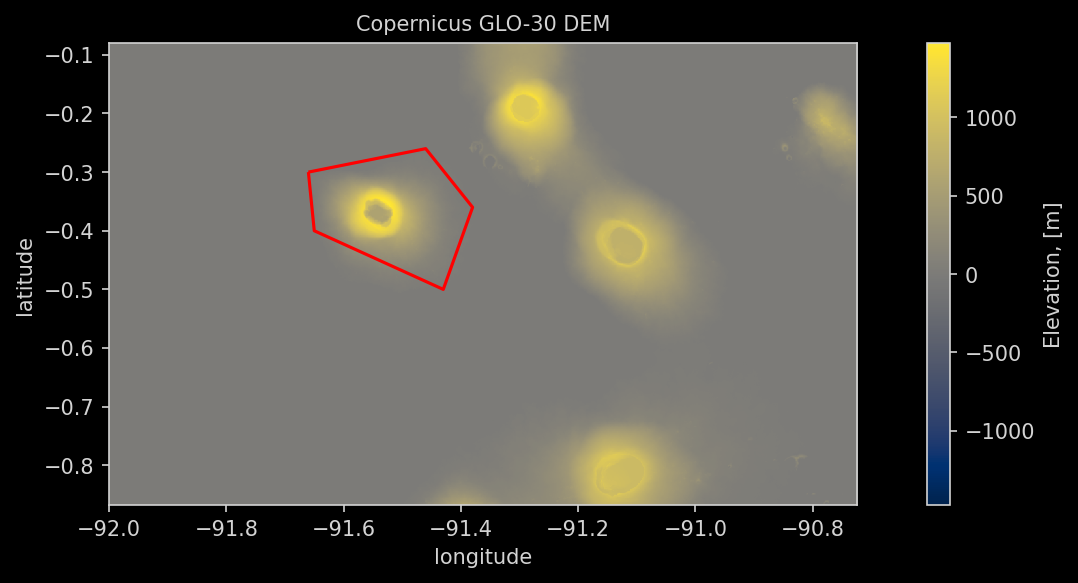

In [ ]:
plt.figure()
# download Copernicus Global DEM 1 arc-second
Tiles().download_dem(s1, provider='GLO', filename=DEM)[::4,::4].plot.imshow(cmap='cividis', cbar_kwargs={'label': 'Elevation, [m]'})
AOI.boundary.plot(ax=plt.gca(), color='red')
plt.title('Copernicus GLO-30 DEM');

## Coregister and geocode

`transform()` writes the Zarr stack: every burst coregistered to the 2020-01-10 reference,
geocoded to UTM, topographic phase removed, chunked for parallel processing. `bbox` crops the
bursts to the island, so the ocean around it is never processed.

In [ ]:
# scan SLC bursts with DEM
s1 = S1(DATADIR, DEM=DEM)
s1

NOTE: Loaded 8 bursts.


Computing Baselines      : 100%|██████████| 8/8 [00:00<00:00, 10.11it/s]

NOTE: baselines are measured from 2020-01-10.


Object S1 8 items
                                                                                         startTime  \
fullBurstID    polarization burst                                                                    
128_273866_IW1 VV           S1_273866_IW1_20200110T114942_VV_5E5F-BURST 2020-01-10 11:49:42.916787   
                            S1_273866_IW1_20200116T115024_VV_D200-BURST 2020-01-16 11:50:24.456341   
128_273866_IW2 VV           S1_273866_IW2_20200110T114943_VV_5E5F-BURST 2020-01-10 11:49:43.858232   
                            S1_273866_IW2_20200116T115025_VV_D200-BURST 2020-01-16 11:50:25.391618   
128_273867_IW1 VV           S1_273867_IW1_20200110T114945_VV_5E5F-BURST 2020-01-10 11:49:45.671232   
                            S1_273867_IW1_20200116T115027_VV_D200-BURST 2020-01-16 11:50:27.204619   
128_273867_IW2 VV           S1_273867_IW2_20200110T114946_VV_5E5F-BURST 2020-01-10 11:49:46.606511   
                            S1_273867_IW2_20200116T115028_VV_D200-BURST 2020-01-16 11:50:28.146064   

                                                                        flightDirection  \
fullBurstID    polarization burst                                                         
128_273866_IW1 VV           S1_273866_IW1_20200110T114942_VV_5E5F-BURST      Descending   
                            S1_273866_IW1_20200116T115024_VV_D200-BURST      Descending   
128_273866_IW2 VV           S1_273866_IW2_20200110T114943_VV_5E5F-BURST      Descending   
                            S1_273866_IW2_20200116T115025_VV_D200-BURST      Descending   
128_273867_IW1 VV           S1_273867_IW1_20200110T114945_VV_5E5F-BURST      Descending   
                            S1_273867_IW1_20200116T115027_VV_D200-BURST      Descending   
128_273867_IW2 VV           S1_273867_IW2_20200110T114946_VV_5E5F-BURST      Descending   
                            S1_273867_IW2_20200116T115028_VV_D200-BURST      Descending   

                                                                         pathNumber  \
fullBurstID    polarization burst                                                     
128_273866_IW1 VV           S1_273866_IW1_20200110T114942_VV_5E5F-BURST         128   
                            S1_273866_IW1_20200116T115024_VV_D200-BURST         128   
128_273866_IW2 VV           S1_273866_IW2_20200110T114943_VV_5E5F-BURST         128   
                            S1_273866_IW2_20200116T115025_VV_D200-BURST         128   
128_273867_IW1 VV           S1_273867_IW1_20200110T114945_VV_5E5F-BURST         128   
                            S1_273867_IW1_20200116T115027_VV_D200-BURST         128   
128_273867_IW2 VV           S1_273867_IW2_20200110T114946_VV_5E5F-BURST         128   
                            S1_273867_IW2_20200116T115028_VV_D200-BURST         128   

                                                                        subswath  \
fullBurstID    polarization burst                                                  
128_273866_IW1 VV           S1_273866_IW1_20200110T114942_VV_5E5F-BURST      IW1   
                            S1_273866_IW1_20200116T115024_VV_D200-BURST      IW1   
128_273866_IW2 VV           S1_273866_IW2_20200110T114943_VV_5E5F-BURST      IW2   
                            S1_273866_IW2_20200116T115025_VV_D200-BURST      IW2   
128_273867_IW1 VV           S1_273867_IW1_20200110T114945_VV_5E5F-BURST      IW1   
                            S1_273867_IW1_20200116T115027_VV_D200-BURST      IW1   
128_273867_IW2 VV           S1_273867_IW2_20200110T114946_VV_5E5F-BURST      IW2   
                            S1_273867_IW2_20200116T115028_VV_D200-BURST      IW2   

                                                                        mission  \
fullBurstID    polarization burst                                                 
128_273866_IW1 VV           S1_273866_IW1_20200110T114942_VV_5E5F-BURST     S1B   
                            S1_273866_IW1_20200116T115024_VV_D200-BURST     S1A   
128_27

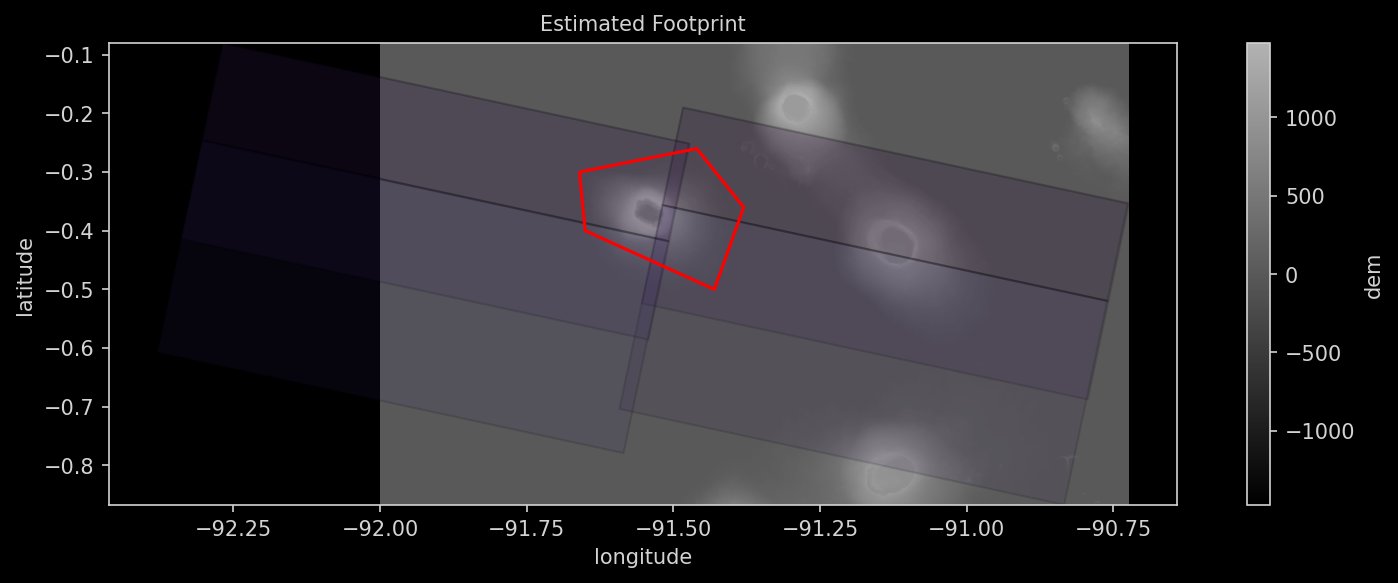

In [ ]:
# descending orbit bursts: preview
s1.plot(ref='2020-01-10')
AOI.boundary.plot(ax=plt.gca(), color='red');

In [ ]:
# load SLC bursts and orbits with DEM and transform to ZARR
s1.transform(ZARRDIR, ref='2020-01-10', bbox=AOI.total_bounds.tolist())

NOTE: EPSG code is computed automatically for all bursts: 32715.


Checking Orbits          : 100%|██████████| 2/2 [00:00<00:00, 23.38it/s]


NOTE: Using 4 workers for 4 bursts, 2 dates each (burst-parallel, scheduler=None).


Transforming SLC...      : 100%|██████████| 4/4 [00:28<00:00,  7.15s/it]


# Stage 2 — Processing: interferogram, unwrapping, LOS displacement

Everything below reads the Zarr stack and needs nothing from Stage 1.

## Load and set up Python modules

In [ ]:
import sys, os
if 'google.colab' in sys.modules:
  #!{sys.executable} -m pip install -qq --progress-bar off insardev insardev-toolkit
  !{sys.executable} -m pip install -qq --progress-bar off \
    "insardev_toolkit  @ git+https://github.com/InSARdev/core@main#subdirectory=insardev_toolkit" \
    "insardev          @ git+https://github.com/InSARdev/core@main#subdirectory=insardev"
  !{sys.executable} -m pip install -qq --progress-bar off  "pyvista<0.49" xvfbwrapper jupyter_bokeh vtk panel
  from google.colab import output
  output.enable_custom_widget_manager()

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# common data science libraries
import numpy as np
import geopandas as gpd
import shapely
from scipy.ndimage import binary_fill_holes
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
# import modules to be used in the notebook
from insardev import Stack
from insardev_toolkit.HTTP import unzip
from insardev_toolkit import UI, Tiles, XYZTiles
UI('dark')

In [ ]:
# 3D plotting modules
import pyvista as pv
pv.set_plot_theme("dark")
from IPython.display import display, HTML
if 'google.colab' in sys.modules:
    import panel
    panel.extension(comms='ipywidgets')
    panel.extension('vtk')

## Directories

In [ ]:
ZARRDIR = 'lacumbre_zarr'
WORKDIR = 'lacumbre_workdir'
LAND = f'{WORKDIR}/land.vrt'

### Volcano location

Defined here rather than carried over from Stage 1, so this half of the notebook runs on its own
from the Zarr.

In [ ]:
# summit of Fernandina volcano (La Cumbre) as located by the Smithsonian Global Volcanism Program
POI = gpd.GeoDataFrame(geometry=[shapely.geometry.Point(-91.55, -0.37)]).set_crs('EPSG:4326')
POI

,geometry
0,POINT (-91.55 -0.37)


## Download and unpack datasets

We can process datasets hosted on GitHub, Zenodo, or other platforms in a single workflow.

In [ ]:
# example downloading command
#unzip("https://zenodo.org/records/15347694/files/Türkiye_Elevation-40x10-004.zip", ZARRDIR)

## Dask cluster

Every step below is lazy — the calls build a task graph and `.compute()` runs it — so a laptop
can process a stack far larger than its memory. The same code runs unchanged on a distributed
cluster.

In [ ]:
if 'client' in globals():
    client.shutdown()
    client.close()
import logging
logging.getLogger('distributed').setLevel(logging.CRITICAL)
from dask.distributed import Client
client = Client(silence_logs='CRITICAL', threads_per_worker=2)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 6
Total threads: 12,Total memory: 52.96 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:36191,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:35843,Total threads: 2
Dashboard: http://127.0.0.1:39607/status,Memory: 8.83 GiB
Nanny: tcp://127.0.0.1:45939,


## Load the stack

`align()` removes the phase discontinuities between the bursts of the two subswaths.

In [ ]:
stack = Stack().load(ZARRDIR).align()
stack

Loading Dataset...       : 100%|██████████| 4/4 [00:00<00:00, 22.67it/s]


Stack containing 4 items for 2 date (128_273866_IW1 … 128_273867_IW2)

In [ ]:
stack.isel(0).data.VV

<xarray.DataArray 'VV' (date: 2, y: 1660, x: 4244)> Size: 113MB
dask.array<mul, shape=(2, 1660, 4244), dtype=complex64, chunksize=(1, 1660, 2122), chunktype=numpy.ndarray>
Coordinates:
  * date         (date) datetime64[s] 16B 2020-01-10T11:49:42 2020-01-16T11:5...
  * y            (y) float64 13kB 9.945e+06 9.945e+06 ... 9.971e+06 9.971e+06
  * x            (x) float64 34kB 6.633e+05 6.633e+05 ... 6.803e+05 6.803e+05
    spatial_ref  int64 8B 0

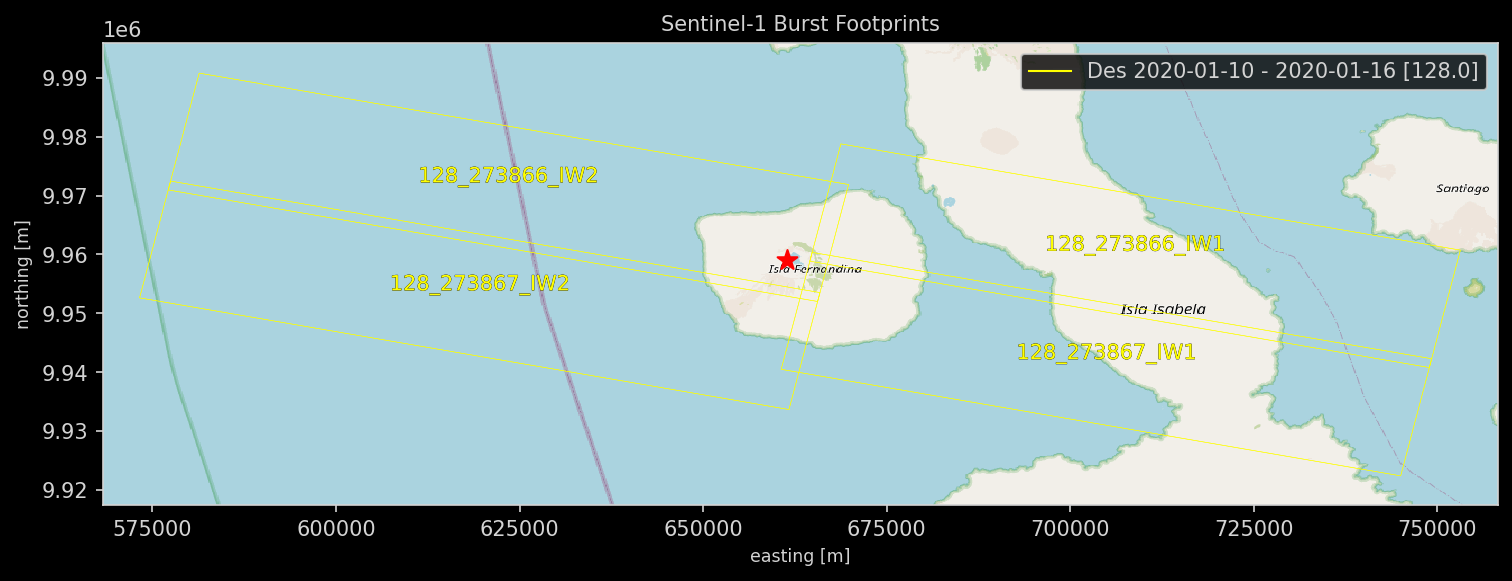

In [ ]:
stack.plot(cmap='autumn', alpha=0.15)
POI.to_crs(stack.crs).plot(marker='*', color='red', markersize=100, ax=plt.gca())
# download the basemap adding the buffer to cover the area of interest after reprojecting
gmap = XYZTiles().download_openstreetmap(stack.to_dataframe().buffer(5_000), zoom=10)
gmap.plot.imshow(ax=plt.gca(), zorder=-1, add_labels=False)
plt.gca().set_title('Sentinel-1 Burst Footprints');

## Land mask

The island is surrounded by the ocean, where the radar phase is pure noise. A 1 arc-second land
mask keeps the land pixels only.

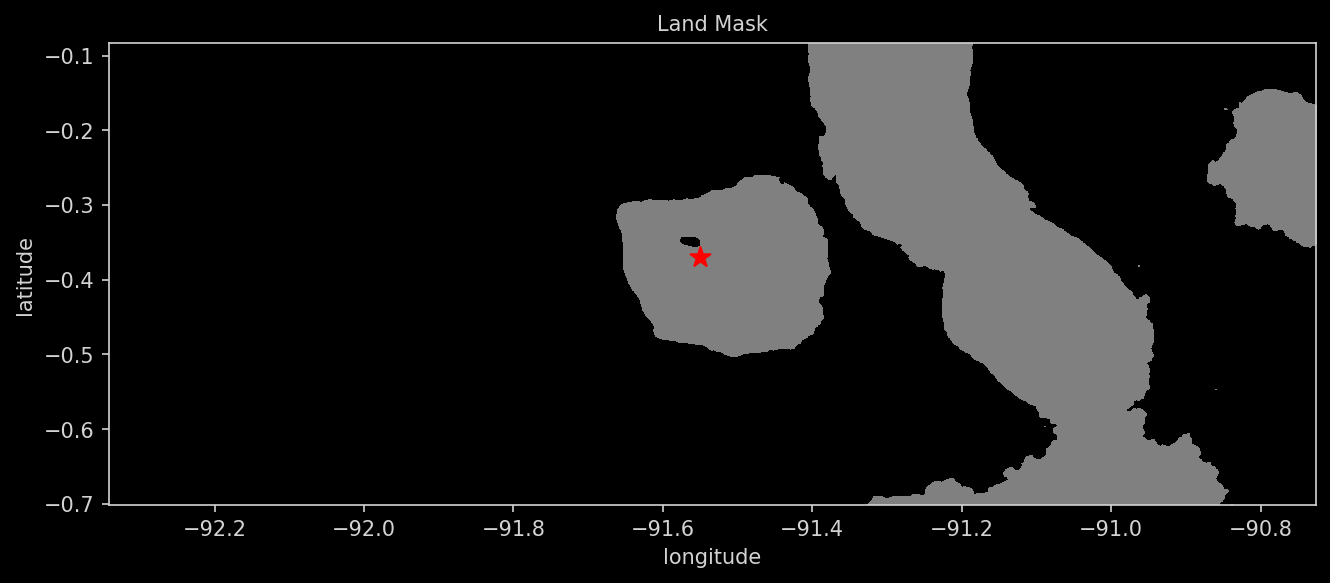

In [ ]:
# download land mask 1 arc-second over the loaded stack's own footprint
Tiles().download_landmask(stack.to_dataframe(), filename=LAND, product='1s').plot.imshow(cmap='binary_r', add_colorbar=False)
POI.plot(marker='*', color='red', markersize=100, ax=plt.gca())
plt.title('Land Mask');

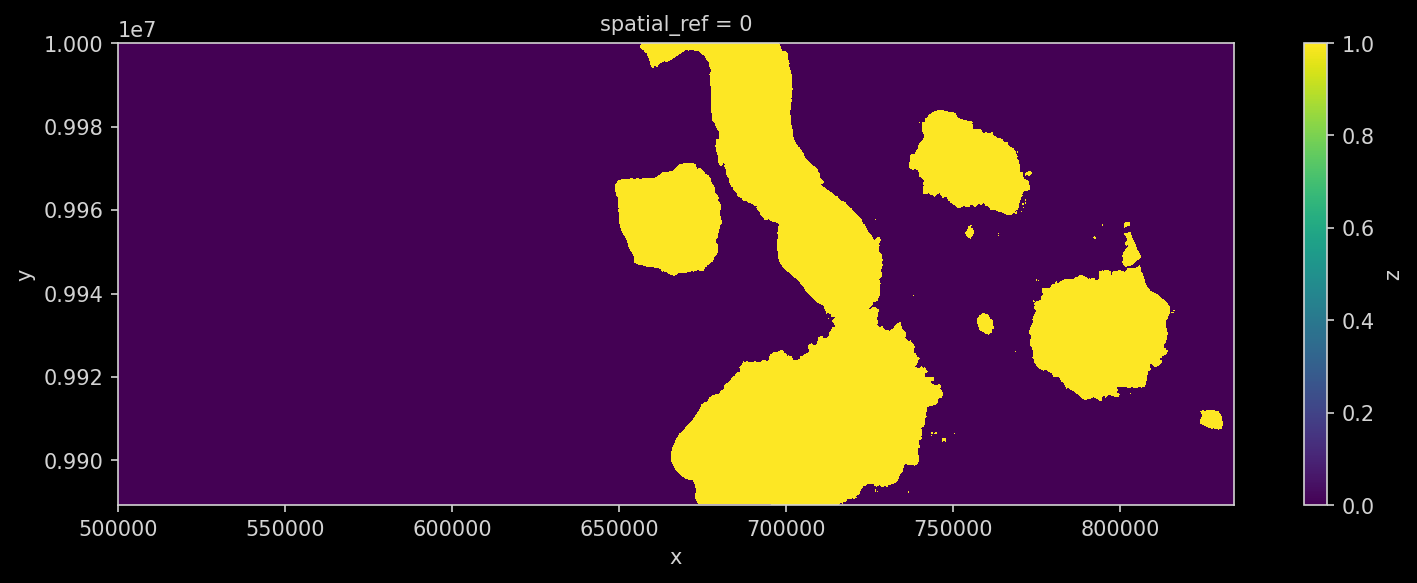

In [ ]:
# load reprojected land mask and convert to binary mask and fill caldera lake area
landmask = np.isfinite(Tiles().open(LAND, crs=stack.crs))
landmask = landmask.copy(data=binary_fill_holes(landmask.values))
landmask.plot.imshow()

## Interferogram

The co-eruptive pair is the two dates of the stack. `interferogram(60)` applies a 60 m Gaussian
anti-aliasing filter and returns the complex interferogram with its correlation, `goldstein(120)`
sharpens the dense fringes near the summit, `angle()` takes the wrapped phase and
`downsample(30)` moves the result to a 30 m grid, as in the PyGMTSAR notebook. `dissolve()`
merges the bursts into one continuous raster.

In [ ]:
# antialiasing Gaussian filter, adaptive Goldstein filter, then multilooking on the land area
intf, corr = stack.pairs([0, 1]).interferogram(60).goldstein(120).angle().mask(landmask).downsample(30).compute()
intf

Computing bursts         : 100%|██████████| 332/332 [00:08<00:00, 39.18it/s]


BatchWrap containing 4 items for 1 pair (128_273866_IW1 … 128_273867_IW2)

In [ ]:
# merge the bursts into one raster
intf = intf.dissolve().compute()
corr = corr.dissolve().compute()

Computing Batch...       : 100%|██████████| 251/251 [00:00<00:00, 2473.85it/s]


Computing VV Plot        : 100%|██████████| 324/324 [00:00<00:00, 3166.63it/s]


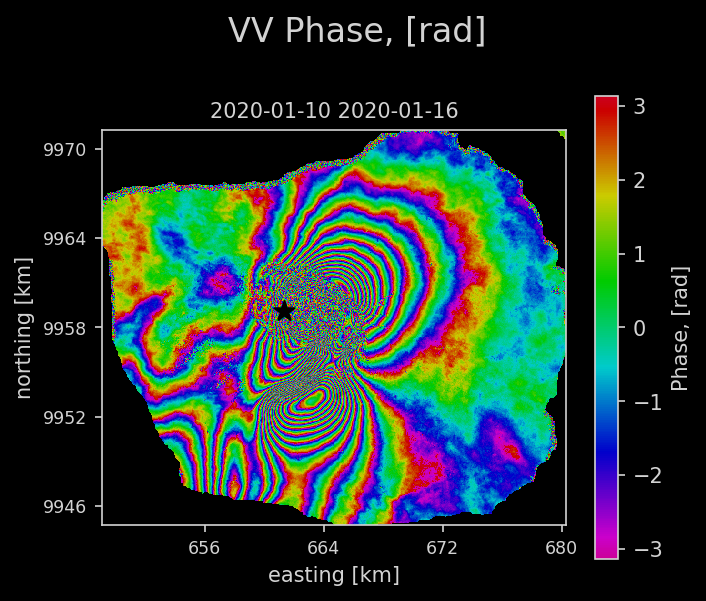

In [ ]:
intf.plot(cmap='gist_rainbow_r', alpha=0.8, caption='Phase, [rad]')
POI.to_crs(stack.crs).plot(marker='*', color='black', markersize=100, ax=plt.gca());

Computing VV Plot        : 100%|██████████| 260/260 [00:00<00:00, 226154.92it/s]


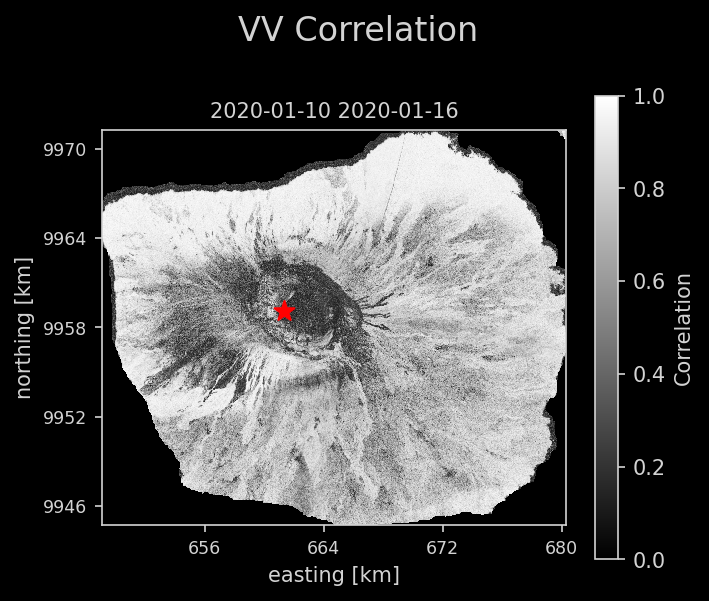

In [ ]:
corr.plot(cmap='gray', alpha=1, caption='Correlation')
POI.to_crs(stack.crs).plot(marker='*', color='red', markersize=100, ax=plt.gca());

## Unwrapping

`unwrap2d()` recovers the integer number of cycles per pixel, weighted by the correlation.
`union=True` unwraps the whole island as a single raster, so no burst boundary can introduce a
step between components.

In [ ]:
phase = intf.unwrap2d(corr, union=True).compute()
phase

Computing Batch...       : 100%|██████████| 436/436 [00:02<00:00, 187.82it/s] 


Batch containing 4 items for 1 pair (128_273866_IW1 … 128_273867_IW2)

Computing VV Plot        : 100%|██████████| 445/445 [00:00<00:00, 496004.59it/s]


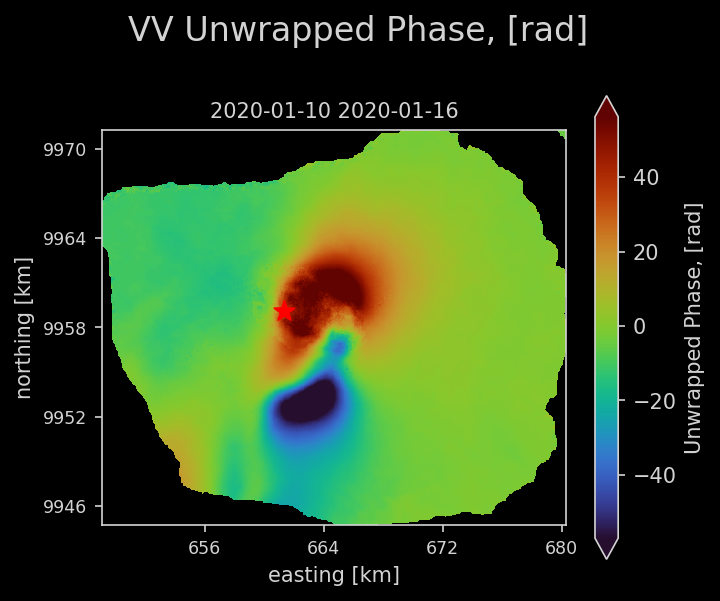

In [ ]:
phase.plot(quantile=[0.01, 0.99], alpha=0.8, caption='Unwrapped Phase, [rad]')
POI.to_crs(stack.crs).plot(marker='*', color='red', markersize=100, ax=plt.gca());

## LOS displacement

`displacement_los()` converts radians to metres with the Sentinel-1 wavelength,
$d = -\frac{\lambda}{4\pi}\varphi$: positive values are motion towards the satellite (uplift on a
descending pass), negative values motion away from it. The unwrapped phase holds an arbitrary
constant, so the displacement is referenced to the median of the island, which moved little
outside the summit area.

In [ ]:
los_mm = (1000 * phase.displacement_los(stack.transform())).compute()
# reference the displacement to the median of the island
los_mm = los_mm - float(los_mm.to_dataset().VV.compute().median())

Computing Batch...       : 100%|██████████| 444/444 [00:00<00:00, 394381.82it/s]


Computing VV Plot        : 100%|██████████| 453/453 [00:00<00:00, 492233.09it/s]


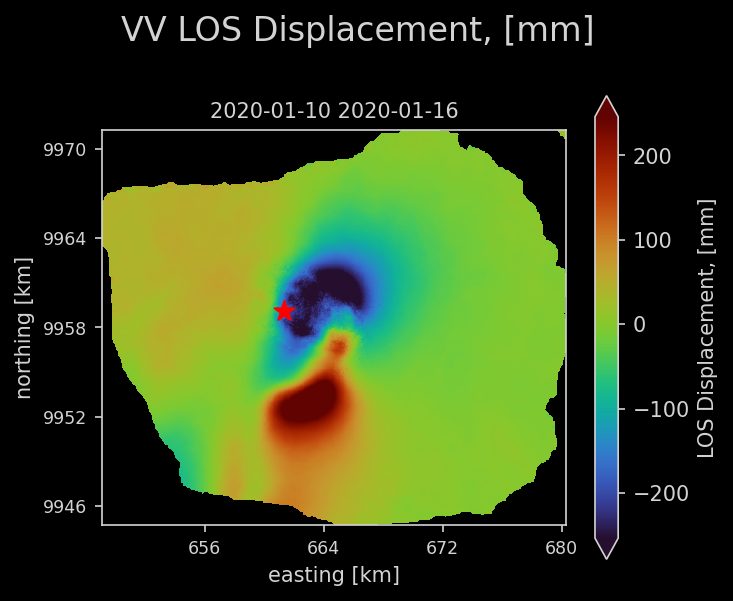

In [ ]:
los_mm.plot(quantile=[0.01, 0.99], alpha=0.8, caption='LOS Displacement, [mm]')
POI.to_crs(stack.crs).plot(marker='*', color='red', markersize=100, ax=plt.gca());

In [ ]:
# LOS displacement range, [mm]
los_values = los_mm.to_dataset().VV
print(f'LOS displacement from {float(los_values.quantile(0.001)):.0f} mm to {float(los_values.quantile(0.999)):.0f} mm (0.1% and 99.9% percentiles)')

LOS displacement from -310 mm to 319 mm (0.1% and 99.9% percentiles)


## 3D interactive map

In [ ]:
# elevation of the stack on the 30 m grid of the results
elevation = stack.transform()[['ele']].downsample(30).compute()
intf.to_vtk('intf', elevation)
los_mm.to_vtk('los', elevation)

Exporting VTK: 100%|██████████| 1/1 [00:00<00:00,  4.36it/s]


In [ ]:
# build interactive 3D plot: the interferogram (left) and the LOS displacement (right) draped on the DEM
plotter = pv.Plotter(shape=(1, 2), notebook=True)
for col, (name, label) in enumerate([('intf', 'Phase, [rad]'), ('los', 'LOS Displacement, [mm]')]):
    plotter.subplot(0, col)
    mesh = pv.read(f'{name}/VV.vtk').scale([1, 1, 1], inplace=True)
    plotter.add_mesh(mesh, scalars='20200110_20200116', cmap='turbo', ambient=0.1,
                     show_scalar_bar=True, scalar_bar_args={'title': label})
    center = mesh.center
    # move camera closer by reducing distance (zoom in)
    distance = mesh.length / 1.4
    plotter.camera.position = (center[0] + distance, center[1] + distance, center[2] + distance * 0.5)
    plotter.camera.focal_point = center
    plotter.camera.azimuth = 215
    plotter.camera.elevation = 20
plotter.link_views()
plot = plotter.show(screenshot='3D La Cumbre.png', jupyter_backend='panel' if 'google.colab' in sys.modules else 'client', return_viewer=True)
if 'google.colab' in sys.modules:
    plot = panel.panel(
        plotter.render_window, orientation_widget=plotter.renderer.axes_enabled,
        enable_keybindings=False, sizing_mode='stretch_width', min_height=600
    )
display(HTML('<h1 style="text-align:center; margin-bottom:0;">Sentinel-1 Interferogram and LOS Displacement on DEM</h1>'))
plot

## Compare results to IG-EPN

The Instituto Geofísico, Escuela Politécnica Nacional (IG-EPN) published the LOS displacement [-35, 21.8] cm of
the same eruption in the Smithsonian Global Volcanism Program Bulletin Report, March 2020
(BGVN 45:03): https://volcano.si.edu/volcano.cfm?vn=353010

The PyGMTSAR notebook measured the LOS displacement from **−350 mm to +218 mm** on the same pair.

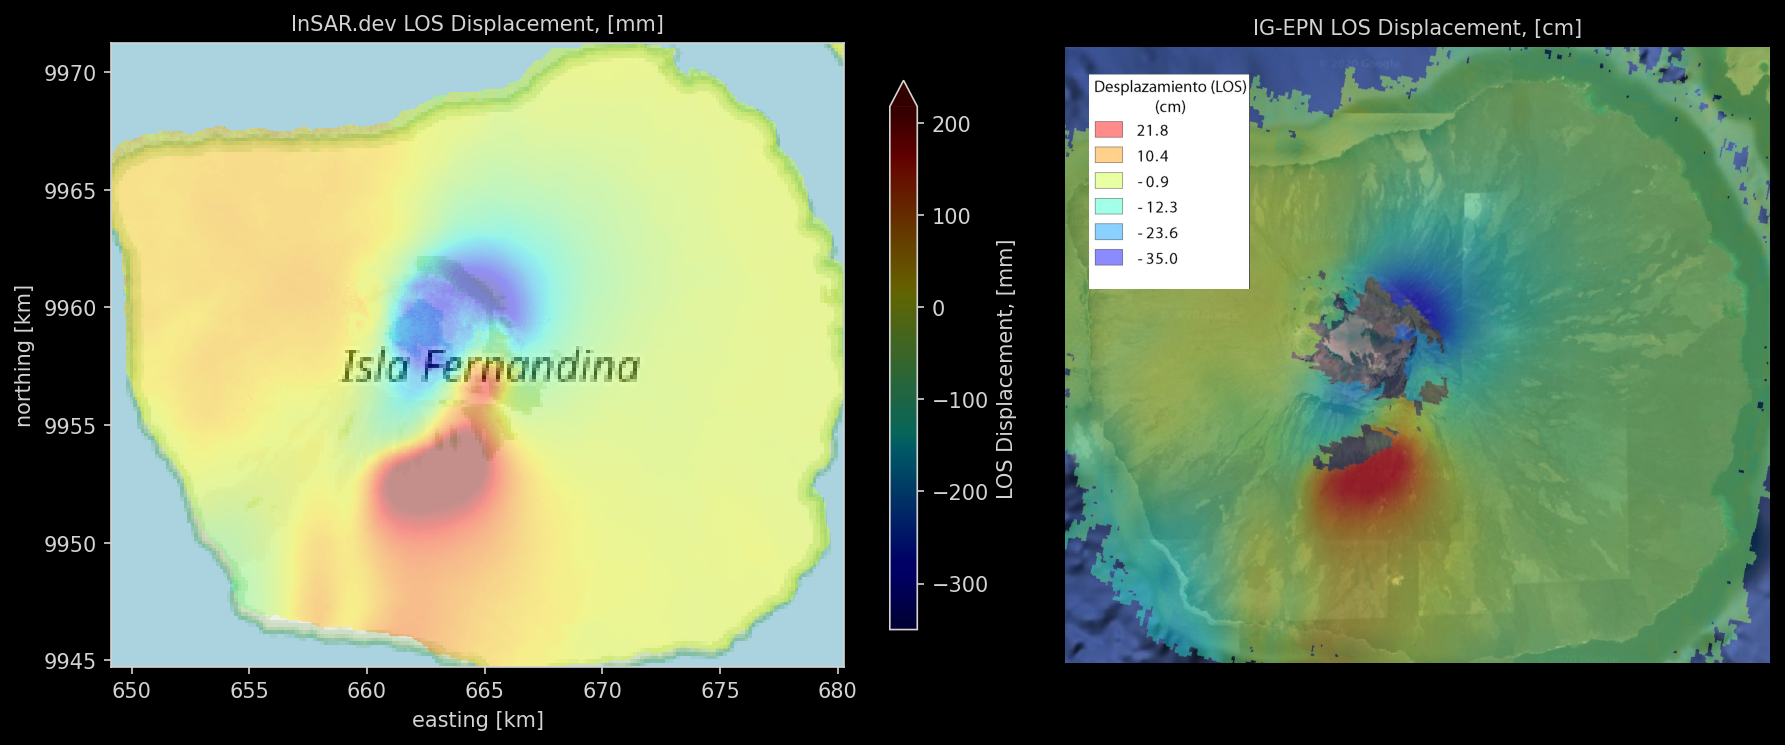

In [ ]:
import requests
from PIL import Image
from io import BytesIO

#fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=150)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=150, width_ratios=[1.3, 1])
gmap.plot.imshow(ax=ax1, add_labels=False)
# the same colour range as the PyGMTSAR comparison
los = los_mm.to_dataset().VV[0]
los.plot.imshow(cmap='jet', alpha=0.4, vmin=-350, vmax=218, ax=ax1, add_labels=False,
                cbar_kwargs={'label': 'LOS Displacement, [mm]', 'shrink': 0.8})
ax1.set_xlim(los.x.min(), los.x.max())
ax1.set_ylim(los.y.min(), los.y.max())
ax1.set_aspect('equal')
# kilometre ticks
ax1.xaxis.set_major_formatter(lambda v, _: f'{v/1000:.0f}')
ax1.yaxis.set_major_formatter(lambda v, _: f'{v/1000:.0f}')
ax1.set_xlabel('easting [km]')
ax1.set_ylabel('northing [km]')
ax1.set_title('InSAR.dev LOS Displacement, [mm]')

# the server does not always respond
try:
    response = requests.get('https://www.igepn.edu.ec/images/portal/noticias/volcanes/galapagos/2020/fernandina20200123-3.jpg', timeout=30)
    response.raise_for_status()
    img = np.asarray(Image.open(BytesIO(response.content)))
    crop = img[717:1826, 720:1989]
    ax2.imshow(crop)
    # IG-EPN legend (title and colour swatches, logos dropped), cropped from the image's top left corner
    legend = img[189:833, 219:700]
    # its offset from the map frame corner in the original image, scaled with the legend
    scale = 0.6
    dy, dx = (189 - 108) * scale, (219 - 147) * scale
    h, w = legend.shape[0] * scale, legend.shape[1] * scale
    ax2.imshow(legend, extent=[dx, dx + w, dy + h, dy])
    ax2.set_xlim(0, crop.shape[1])
    ax2.set_ylim(crop.shape[0], 0)
except Exception as e:
    ax2.text(0.5, 0.5, f'IG-EPN image is not available:\n{e}', ha='center', va='center', wrap=True)
ax2.axis('off')
ax2.set_title('IG-EPN LOS Displacement, [cm]')
plt.tight_layout()
plt.show()

## Save the results

GeoTIFF and NetCDF files open in QGIS and other GIS applications.

In [ ]:
# LOS displacement in millimetres as a GeoTIFF in the stack's UTM projection
los_mm.to_dataset().VV[0].rio.to_raster('los.tif')
los_mm.to_dataset().VV[0].to_netcdf('los.nc')

## Export from Google Colab

In [ ]:
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download('los.tif')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>